# Lab 2 — What Did the Campaign Deliver?
Name: Artem Khailo | Group: KM-42

## Setup

In [45]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Size

In [46]:
brand_a= commercials[commercials["brand"]=="BRAND_A"]

print("Spots:", len(commercials))
print("Pods:", commercials["pod_id"].nunique())
print("Brands:", commercials["brand"].nunique())
print("Categories:", commercials["category"].nunique())
print("BRAND_A spots:", len(brand_a))
print(brand_a["network_code"].value_counts())

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300
network_code
FNC      40
HGTV     39
FX       38
HIST     37
BRAVO    33
FOOD     33
ABC      29
CBS      22
NBC      16
FOX      13
Name: count, dtype: int64


## Task 1.2 — Ad load

In [47]:
ads= commercials.assign(hour=commercials["start_ts"].dt.floor("h"))
per_hour= ads.groupby(["network_code", "hour"])["length_sec"].sum()
ad_load= (per_hour.groupby("network_code").mean()/60).sort_values(ascending=False)
print(ad_load.round(1))
print("Heaviest ad load:", ad_load.idxmax())

network_code
FNC      15.6
BRAVO    13.4
HGTV     13.3
HIST     13.2
FOOD     13.1
FX       12.9
CBS      12.1
ABC      11.8
NBC      11.8
FOX      11.8
Name: length_sec, dtype: float64
Heaviest ad load: FNC


**Answer:** Fox News carries the heaviest ad load, about 15.6 minutes of ads per hour; the cable networks have about 13 minutes and the four broadcast networks about 12. The broadcast networks have whole hours without national ads because they do not fill the whole day themselves: many hours are given to their local stations as Local / Syndicated Programming and the ad breaks in those hours are sold locally, so they are not in this national ad log. There are also no national spots in the vice-presidential debate.

## Task 1.3 — Price everything

In [48]:
def to_minutes(t):
    h, m = t.split(":")
    return int(h) * 60 + int(m) - 360

spots= commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id")
spots["bday"] =spots["start_ts"] - pd.Timedelta(hours=6)
spots["weekday"] =spots["bday"].dt.dayofweek
spots["minute"] =spots["bday"].dt.hour * 60 + spots["bday"].dt.minute

times =rate_card[rate_card["program_name"].isna()].explode("weekdays")
times["weekday"] =times["weekdays"].astype(int)
times["start"] =times["start_time"].apply(to_minutes)
times["end"] =times["end_time"].apply(to_minutes)
times = times[["network_code", "weekday", "start", "end", "daypart", "cost_30s_usd"]]

spots= spots.merge(times, on=["network_code", "weekday"])
spots= spots[(spots["start"] <= spots["minute"]) & (spots["minute"] < spots["end"])]

progs= rate_card[rate_card["program_name"].notna()][["network_code", "program_name", "daypart", "cost_30s_usd"]]
spots= spots.merge(progs, on=["network_code", "program_name"], how="left", suffixes=("", "_prog"))
spots["program_row"]=spots["cost_30s_usd_prog"].notna()
spots["daypart"]=spots["daypart_prog"].fillna(spots["daypart"])
spots["price_30s"]=spots["cost_30s_usd_prog"].fillna(spots["cost_30s_usd"])
spots["cost"]=spots["price_30s"] * spots["length_sec"] / 30

print("Spots without a price:", len(commercials) - spots["cost"].notna().sum())
value = spots.groupby("network_code")["cost"].sum()
sports = spots[spots["program_row"]].groupby("network_code")["cost"].sum()
table = pd.DataFrame({"Value (USD M)": value / 1e6, "Share from program rows": sports / value}).fillna(0)
print(table.round({"Value (USD M)": 1, "Share from program rows": 3}).sort_values("Value (USD M)", ascending=False))

Spots without a price: 0
              Value (USD M)  Share from program rows
network_code                                        
CBS                   818.8                    0.230
NBC                   724.3                    0.342
ABC                   708.8                    0.432
FOX                   696.2                    0.835
FNC                   315.8                    0.000
HGTV                   58.1                    0.000
FX                     42.5                    0.000
FOOD                   42.1                    0.000
HIST                   40.1                    0.000
BRAVO                  25.3                    0.000


## Task 2.1 — Delivery

In [49]:
pv=viewings[viewings["resp_type"].isin(["R", "L"])]
camp=spots[spots["brand"] == "BRAND_A"]
rows=[]
for s in camp.itertuples():
    seen=pv[(pv["network_code"] == s.network_code) & (pv["start_ts"] <= s.start_ts) & (pv["end_ts"] > s.start_ts)]
    rows.append(pd.DataFrame({"ad_airing_id": s.ad_airing_id, "respondent_id": seen["respondent_id"].unique(), "broadcast_date": s.bday.normalize()}))
exposures=pd.concat(rows, ignore_index=True)

age=viewer_attributes[viewer_attributes["attr_id"] == 300].set_index("respondent_id")["value"]
dw=daily_weights[daily_weights["resp_type"].isin(["R", "L"])].copy()
dw["broadcast_date"]=pd.to_datetime(dw["broadcast_date"])
dw["target"]=dw["respondent_id"].map(age).between(18, 49)

exposures=exposures.merge(dw, on=["respondent_id", "broadcast_date"])

def delivery(exp, people):
    universe= people.groupby("broadcast_date")["weight"].sum()
    spot_imp= exp.groupby(["ad_airing_id", "broadcast_date"])["weight"].sum().reset_index()
    grps= (spot_imp["weight"] / spot_imp["broadcast_date"].map(universe) * 100).sum()
    monthly= people.groupby("respondent_id")["weight"].mean()
    reach= monthly[monthly.index.isin(exp["respondent_id"])].sum() / monthly.sum() * 100
    return exp["weight"].sum() / 1e6, grps, reach, grps / reach

p_imp, p_grps, p_reach, p_freq = delivery(exposures, dw)
t_imp, t_grps, t_reach, t_freq = delivery(exposures[exposures["target"]], dw[dw["target"]])

print("P2+ impressions (M):", round(p_imp, 1))
print("P2+ GRPs:", round(p_grps, 1))
print("P2+ reach (%):", round(p_reach, 1))
print("P2+ average frequency:", round(p_freq, 1))
print("A18-49 impressions (M):", round(t_imp, 1))
print("A18-49 GRPs:", round(t_grps, 1))
print("A18-49 reach (%):", round(t_reach, 1))
print("A18-49 average frequency:", round(t_freq, 1))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

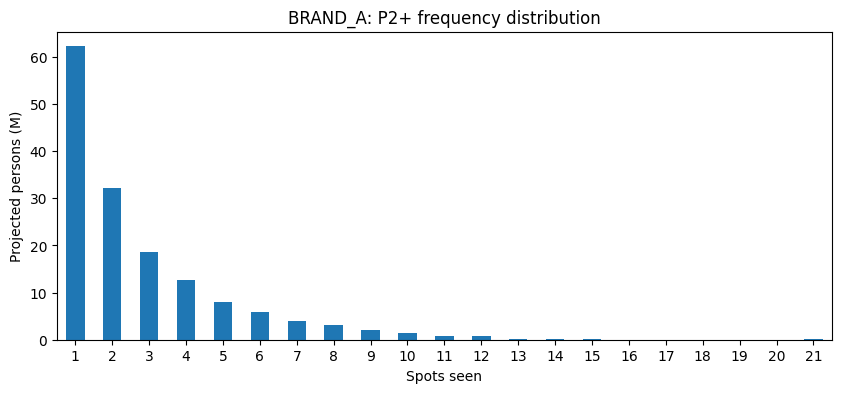

Share of impressions at 5+ exposures: 0.444


In [50]:
freq= exposures.groupby("respondent_id")["ad_airing_id"].nunique()
monthly= dw.groupby("respondent_id")["weight"].mean()
dist=monthly[freq.index].groupby(freq).sum() / 1e6
dist=dist.reindex(range(1, freq.max() + 1), fill_value=0)

ax= dist.plot.bar(figsize=(10, 4), rot=0)
ax.set_xlabel("Spots seen")
ax.set_ylabel("Projected persons (M)")
ax.set_title("BRAND_A: P2+ frequency distribution")
plt.show()

heavy= freq[freq >= 5].index
share_5plus= exposures[exposures["respondent_id"].isin(heavy)]["weight"].sum() / exposures["weight"].sum()
print("Share of impressions at 5+ exposures:", round(share_5plus, 3))

**Answer:** No. The average frequency is 3.0, but the distribution falls steadily: the biggest bars are 1 spot (about 62 M people) and 2 spots (about 32 M), and every next bar is smaller. At the same time the people who saw 5 or more spots got 44.4% of all impressions, although on the plot they are only the small bars on the right. So a minority of heavy viewers saw the ad many times and pulls the average up, while the typical reached person saw it once or twice. The average hides this, so the whole distribution should be shown.

## Task 2.3 — On target?

In [51]:
print("Share of impressions on A18-49:", round(t_imp / p_imp, 3))

exp_net=exposures.merge(camp[["ad_airing_id", "network_code"]], on="ad_airing_id")
imp=exp_net.groupby("network_code")["weight"].sum()
imp_t=exp_net[exp_net["target"]].groupby("network_code")["weight"].sum()
by_net=pd.DataFrame({"P2+ impressions (M)": imp / 1e6, "Share on A18-49": imp_t / imp})
print(by_net.round({"P2+ impressions (M)": 1, "Share on A18-49": 3}).sort_values("Share on A18-49"))

Share of impressions on A18-49: 0.194
              P2+ impressions (M)  Share on A18-49
network_code                                      
FNC                          57.8            0.047
CBS                          89.0            0.154
ABC                          94.2            0.180
NBC                          41.4            0.189
HIST                         12.3            0.202
FOX                          76.3            0.242
HGTV                         24.7            0.306
FOOD                          9.5            0.316
BRAVO                         5.1            0.554
FX                            8.5            0.651


**Answer:** The plan under-delivered against its target. Only 0.194 of all impressions landed on adults 18–49, while they are about 42% of all persons, so the target got less than half of its fair share. The networks that carried most of the impressions are the ones that explain it: CBS (89.0 M impressions, 0.154 on target), ABC (94.2 M, 0.180) and Fox News (57.8 M, only 0.047) mostly reached older viewers, and NBC and FOX are also below 0.42. Only FX (0.651) and Bravo (0.554) delivered above the target's share, but they gave very few impressions (8.5 M and 5.1 M).

## Task 3.1 — Cost

In [52]:
cost=camp["cost"].sum()
print("Campaign cost (USD):", round(cost))
print("P2+ CPM (USD):", round(cost / (p_imp*1e6) *1000, 2))
print("P2+ CPP (USD):", round(cost / p_grps))
print("A18-49 CPM (USD):", round(cost / (t_imp*1e6) *1000, 2))
print("A18-49 CPP (USD):", round(cost / t_grps))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [53]:
net_cost = camp.groupby("network_code")["cost"].sum()
net = pd.DataFrame({"Spots": camp.groupby("network_code").size(), "Cost (USD)": net_cost.round().astype(int),"P2+ impressions (M)": (imp / 1e6).round(1),"P2+ CPM (USD)": (net_cost / imp * 1000).round(2),
                    "A18-49 CPM (USD)": (net_cost / imp_t * 1000).round(2)})
print(net.sort_values("Cost (USD)", ascending=False).to_string())

              Spots  Cost (USD)  P2+ impressions (M)  P2+ CPM (USD)  A18-49 CPM (USD)
network_code                                                                         
FOX              13     2434700                 76.3          31.93            132.03
ABC              29     1625700                 94.2          17.26             95.69
CBS              22     1488700                 89.0          16.73            108.72
NBC              16      796800                 41.4          19.23            101.72
FNC              40      526300                 57.8           9.11            193.70
HGTV             39      230000                 24.7           9.33             30.45
FOOD             33       96620                  9.5          10.19             32.29
FX               38       92200                  8.5          10.82             16.61
HIST             37       79640                 12.3           6.46             32.05
BRAVO            33       49610                  5.1  

**Answer:** Most of the money went to the four broadcast networks: FOX cost \$2,434,700 for only 13 spots, ABC \$1,625,700 and CBS \$1,488,700, while the five small networks cost less than \$250,000 each. The cheapest way to reach the target was FX (A18-49 CPM \$16.61) and Bravo (\$17.61), followed by HGTV, History and Food Network (about \$30–32). The broadcast networks cost \$95.69–132.03 per thousand target impressions, and Fox News was the most expensive for the target (\$193.70), even though it is one of the cheapest for P2+ (\$9.11).

## Task 3.3 — Guarantee

In [54]:
owed=max(150-p_grps, 0)
print("Guarantee met:", p_grps >= 150)
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", round(owed * cost / p_grps))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [55]:
big=["CBS", "NBC", "ABC", "FOX", "FNC"]
def reach_of(exp):
    return monthly[monthly.index.isin(exp["respondent_id"])].sum() / monthly.sum() * 100

r_big=reach_of(exp_net[exp_net["network_code"].isin(big)])
r_small=reach_of(exp_net[~exp_net["network_code"].isin(big)])
r_all=reach_of(exp_net)
overlap=r_big + r_small - r_all
cost_big=camp[camp["network_code"].isin(big)]["cost"].sum()
cost_small=camp[~camp["network_code"].isin(big)]["cost"].sum()

print("Reach, big networks (%):", round(r_big, 1))
print("Reach, small networks (%):", round(r_small, 1))
print("Reach, whole campaign (%):", round(r_all, 1))
print("Overlap (%):", round(overlap, 1))
print("Overlap if independent (%):", round(r_big * r_small / 100, 1))
print("Reach added by small networks (points):", round(r_all - r_big, 1))
print("Cost per added reach point, small (USD):", round(cost_small / (r_all - r_big)))
print("Cost per reach point, big (USD):", round(cost_big / r_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** The big networks reached 39.8% of persons and the small ones 12.4%, but the whole campaign reached only 43.5%, not their sum. Reach counts each person once, and 8.7% of persons saw the ad on both groups of networks, so adding the two reaches would count them twice. The overlap of 8.7% is bigger than the 4.9% we would expect if the two audiences were independent, so the viewers of the small networks were more likely than average to be reached by the big networks too: most of the people reached on small networks (8.7 of their 12.4 points) also saw a spot on a big network. A likely reason is that these are heavy TV viewers who watch many channels, so they meet the ad on both. Still, the small-network money was well spent: they added 3.7 points of reach at \$148,706 per point, cheaper than the \$172,456 per reach point on the big networks.

## Task 5 — How sure are we?

In [56]:
sp= camp[["ad_airing_id", "network_code"]].copy()
sp["broadcast_date"] =camp["bday"].dt.normalize()
sp["panelists"] =sp["ad_airing_id"].map(exposures.groupby("ad_airing_id").size()).fillna(0)
sp["p"]= (sp["ad_airing_id"].map(exposures.groupby("ad_airing_id")["weight"].sum()).fillna(0)
           / sp["broadcast_date"].map(dw.groupby("broadcast_date")["weight"].sum()))
sp["n"]= sp["broadcast_date"].map(dw.groupby("broadcast_date").size())
sp["se"] = (sp["p"] * (1 - sp["p"]) / sp["n"]) ** 0.5 * 100
sp["rel_se"] = sp["se"] / (sp["p"] * 100)
sp["big"] = sp["network_code"].isin(big)

print(sp.groupby("network_code")[["panelists", "rel_se"]].median().round(3)
        .rename(columns={"panelists": "Median panelists", "rel_se": "Median relative SE"}))
print("Spots seen by no panelist:", (sp["panelists"] == 0).sum())
print(sp[sp["panelists"] == 0]["network_code"].value_counts())
print("Median relative SE, big networks:", round(sp.loc[sp["big"], "rel_se"].median(), 3))
print("Median relative SE, small networks:", round(sp.loc[~sp["big"], "rel_se"].median(), 3))

women= viewer_attributes[viewer_attributes["attr_id"] == 202]["respondent_id"]
w1834= women[women.map(age).between(18, 34)]
seen_w= exposures[exposures["respondent_id"].isin(w1834)]["ad_airing_id"].nunique()
print("W18-34 zero-cell spots:", len(camp) - seen_w)

              Median panelists  Median relative SE
network_code                                      
ABC                       57.0               0.123
BRAVO                      3.0               0.540
CBS                       69.0               0.113
FNC                       31.0               0.164
FOOD                       5.0               0.423
FOX                      145.0               0.080
FX                         5.5               0.423
HGTV                      11.0               0.301
HIST                       5.0               0.460
NBC                       68.5               0.115
Spots seen by no panelist: 10
network_code
FX       4
BRAVO    3
FOOD     2
HIST     1
Name: count, dtype: int64
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** 10 BRAND_A spots were seen by no panelist, and all of them ran on small networks (FX, Bravo, Food Network, History). Such a spot gets a rating of exactly 0, but this does not mean that nobody in the US saw it: the panel is simply too small to catch the few people who watch a small network at that moment. On the small networks a typical spot is seen by only 3–11 panelists, against 31–145 on the big ones, and the median relative error is 0.417 (about ±42% of the rating) against 0.122 on the big networks; the 10 zero-rating spots have no relative error and are left out of these medians. So small-network ratings are very uncertain, and the real errors are even larger, because a weighted panel behaves like a smaller one. For W18–34, 171 of the 300 spots were not seen by a single woman aged 18–34 in the panel. I would tell the client that W18–34 ratings spot by spot cannot be reported reliably: more than half of the spot ratings would be exactly zero, so we can only give a W18–34 number for the whole campaign, or use a bigger target such as A18–49.

## Bonus

**Answer:** I would move the budget of 20 of the 40 Fox News spots (about \$263,000, half of its \$526,300) to FX and Bravo. On Fox News this money buys only about 1.4 M A18-49 impressions (A18-49 CPM \$193.70), while at the FX and Bravo target CPMs (\$16.61 and \$17.61) it would buy about 15 M, so the campaign's A18-49 impressions would rise from 81.1 M to about 95 M and its A18-49 CPM would fall from \$91.53 to about \$78. P2+ impressions would drop only a little (P2+ CPM \$9.11 on Fox News vs \$10.82 and \$9.76), so the GRP shortfall would grow by only about 1 GRP. The risk is that this means about 130 more spots on small networks with small audiences, so part of the new impressions would be repeat exposures, and from Task 5 their ratings are much less certain.